# Assignment:02 ANN & Deep Learning
### Resnet and Unet

| | |
|---|---|
| **Name** | Ahmad Liaqat_________________ |
| **Roll No.** | BSCS23067_____________________ |

---


>
> **Grading (100 marks)**
>
> | Part | Marks |
> |---|---:|
> | Dataset setup, exploration, preprocessing, split (Tasks 1-4, 12-14) | 20 |
> | ResNet-50 modification, training and evaluation (Tasks 5-11) | 25 |
> | U-Net loss, metrics, training and evaluation (Tasks 15-20) | 25 |
> | Results tables (Task 21) and filled-in reports | 5 |
> | Discussion questions and conclusion | 15 |
> | GitHub repository, README, code quality / comments | 10 |

# Table of Contents
1. Introduction
2. Learning Objectives
3. Datasets - where to download them and how to upload them to Google Drive
4. **Step 1** - Environment setup (libraries, GPU, reproducibility)
5. **Step 2** - Mount Google Drive and set the dataset paths
6. **Part A - ResNet-50 Fine-Tuning (Classification)**
    * Step 3 - Explore the flower dataset
    * Step 4 - Preprocessing, augmentation and train/validation/test split
    * Step 5 - ResNet-50 architecture and loading the pretrained model
    * Step 6 - Training utilities
    * Step 7 - Phase 1: feature extraction (frozen backbone)
    * Step 8 - Phase 2: fine-tuning (unfreeze `layer4`)
    * Step 9 - Training curves
    * Step 10 - Evaluation on the test set
7. **Part B - U-Net Fine-Tuning (Segmentation)**
    * Step 11 - Explore the pet segmentation dataset
    * Step 12 - Joint image/mask preprocessing, split and loaders
    * Step 13 - U-Net architecture and model creation
    * Step 14 - Loss function and metrics
    * Step 15 - Phase 1: train the decoder (frozen encoder)
    * Step 16 - Phase 2: fine-tune the encoder
    * Step 17 - Evaluation and visualization






# Introduction
Training a deep convolutional network from scratch needs **tens of thousands of labelled images** and a lot of compute. In practice (medical imaging, agriculture, small company datasets) we often have only **100-200 images**. In such cases we rely on **transfer learning**: we start from a network that was already trained on a very large dataset (ImageNet, 1.2 million images) and **adapt** it to our own small dataset. This adaptation step is called **fine-tuning**.

In this assignment you will fine-tune two of the most important CNN families in computer vision:

| Model | Task | Idea |
|---|---|---|
| **ResNet-50** | Image **classification** (what is in the image?) | Deep CNN with *residual (skip) connections* and bottleneck blocks |
| **U-Net** (with a ResNet-50 encoder) | Image **segmentation** (which pixels belong to the object?) | Encoder-decoder network with *skip connections* between encoder and decoder |



# Datasets (Download -> Upload to Google Drive)

Use **two small datasets** (about **100-200 images** each).

| | Dataset 1 (classification) | Dataset 2 (segmentation) |
|---|---|---|
| **Name** | Oxford Flowers-102 (small subset) | Oxford-IIIT Pet (small subset) |
| **Official page / download** | https://www.robots.ox.ac.uk/~vgg/data/flowers/102/ | https://www.robots.ox.ac.uk/~vgg/data/pets/ |
| **Files** | `102flowers.tgz`, `imagelabels.mat` | `images.tar.gz`, `annotations.tar.gz` |
| **Size to use** | 5 classes x 40 images = **200 images** | **150 image + mask pairs** |
| **Used by** | ResNet-50 | U-Net |


### Required folder structure on Google Drive
```text
MyDrive/
└── ANN_DL_Assignment/
    ├── flowers_subset/              <- classification dataset (ImageFolder format)
    │   ├── flower_class_000/  *.jpg
    │   ├── flower_class_001/  *.jpg
    │   └── ...
    └── pets_subset/                 <- segmentation dataset
        ├── images/   *.jpg
        └── masks/    *.png          <- same file name as the image
```
For the pet masks, the original *trimap* convention is kept: `1 = pet`, `2 = background`, `3 = border`.


# Step 1: Environment Setup
**Before running:** in Colab choose **Runtime -> Change runtime type -> T4 GPU**. Training ResNet-50 and U-Net on a CPU is very slow.

We install `segmentation-models-pytorch` (SMP), which provides U-Net with pretrained encoders, and import all libraries. We also fix the random seeds so that results are **reproducible**.

In [1]:
# Install the segmentation library (U-Net with pretrained encoders)
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [2]:
# ---------------- Standard libraries ----------------
import os, random, shutil, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---------------- PyTorch ----------------
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, transforms
import torchvision.transforms.functional as TF

# ---------------- Scikit-learn (splitting + metrics) ----------------
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

# ---------------- U-Net library ----------------
import segmentation_models_pytorch as smp

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------------- Device ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("Using device    :", device)
if device.type == "cpu":
    print("WARNING: no GPU found. Go to Runtime > Change runtime type > T4 GPU.")



PyTorch version : 2.11.0+cu130
Using device    : cuda


In [3]:
# ImageNet statistics: pretrained models expect inputs normalized with them
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Step 2: Mount Google Drive and Set Paths
Colab's local disk is erased when the runtime restarts. **Google Drive** keeps the datasets and trained models permanently. After running the cell below, Google asks for permission to access your Drive - click **Allow**.

In [4]:
from google.colab import drive

# Mount Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# ---------------- Paths (change BASE_DIR if your folder has a different name) ----------------
BASE_DIR     = "/content/drive/MyDrive/ANN_DL_Assignment"      # main assignment folder on Drive
FLOWERS_DIR  = os.path.join(BASE_DIR, "flowers_subset")    # classification dataset
PETS_DIR     = os.path.join(BASE_DIR, "pets_subset")       # segmentation dataset
PET_IMG_DIR  = os.path.join(PETS_DIR, "images")
PET_MASK_DIR = os.path.join(PETS_DIR, "masks")
CKPT_DIR     = os.path.join(BASE_DIR, "checkpoints")       # trained weights are saved here (Drive)
RESULTS_DIR  = "/content/results"                          # figures/tables (copied to Drive at the end)

for d in [BASE_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print("Base folder exists:", os.path.isdir(BASE_DIR))

Base folder exists: True


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
# PART A - ResNet-50 Fine-Tuning (Classification)
---
# Step 3: Explore the Flower Dataset
Always inspect your data before training: how many images, how many classes, is the dataset balanced, what do images look like, and what sizes do they have?

### Task 1 — Count and plot the images (Step 3)
Complete the cell below.

1. **(1a)** Fill the dictionary `counts` so that it maps each class folder name to its number of images. *Hint:* `os.listdir(os.path.join(FLOWERS_DIR, c))` lists the files of class `c`.
2. **(1b)** Print the number of classes, the total number of images, and the images per class.
3. **(1c)** Draw a bar chart of the class distribution with `plt.bar`.

**Report:** number of classes = 5, total number of images = 200

Classes found : 5
Total images  : 200
    flower_class_001 -> 40 images
    flower_class_002 -> 40 images
    flower_class_003 -> 40 images
    flower_class_004 -> 40 images
    flower_class_005 -> 40 images


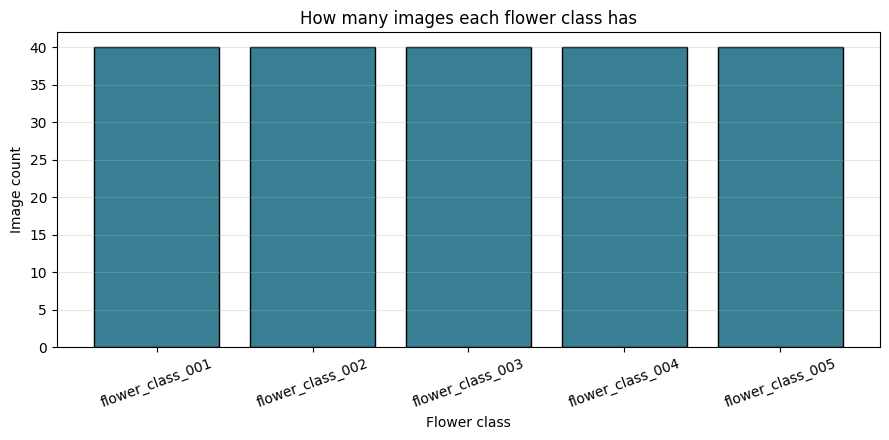

In [7]:
# List of class folders (given)
class_dirs = sorted(d for d in os.listdir(FLOWERS_DIR) if os.path.isdir(os.path.join(FLOWERS_DIR, d)))

# (1a) counts = {class_name: number_of_images}
counts = {}
# WRITE YOUR CODE HERE
imageTypes = (".jpg", ".jpeg", ".png")
for className in class_dirs:
    classFolder = os.path.join(FLOWERS_DIR, className)
    counts[className] = sum(1 for f in os.listdir(classFolder) if f.lower().endswith(imageTypes))

# (1b) print number of classes, total images and images per class
# WRITE YOUR CODE HERE
totalImages = sum(counts.values())
print(f"Classes found : {len(counts)}")
print(f"Total images  : {totalImages}")
for className, numImages in counts.items():
    print(f"{className:>20} -> {numImages} images")

# (1c) bar chart of the class distribution
# WRITE YOUR CODE HERE
plt.figure(figsize=(9, 4.5))
plt.bar(counts.keys(), counts.values(), color="#397F93", edgecolor="black")
plt.title("How many images each flower class has")
plt.xlabel("Flower class")
plt.ylabel("Image count")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Task 2 — Show one sample per class (Step 3)
For every class display **one image** with its **class name** and **size (width x height)** in the title.
*Hint:* `Image.open(path).convert("RGB")` gives a PIL image; `img.size` gives `(width, height)`.

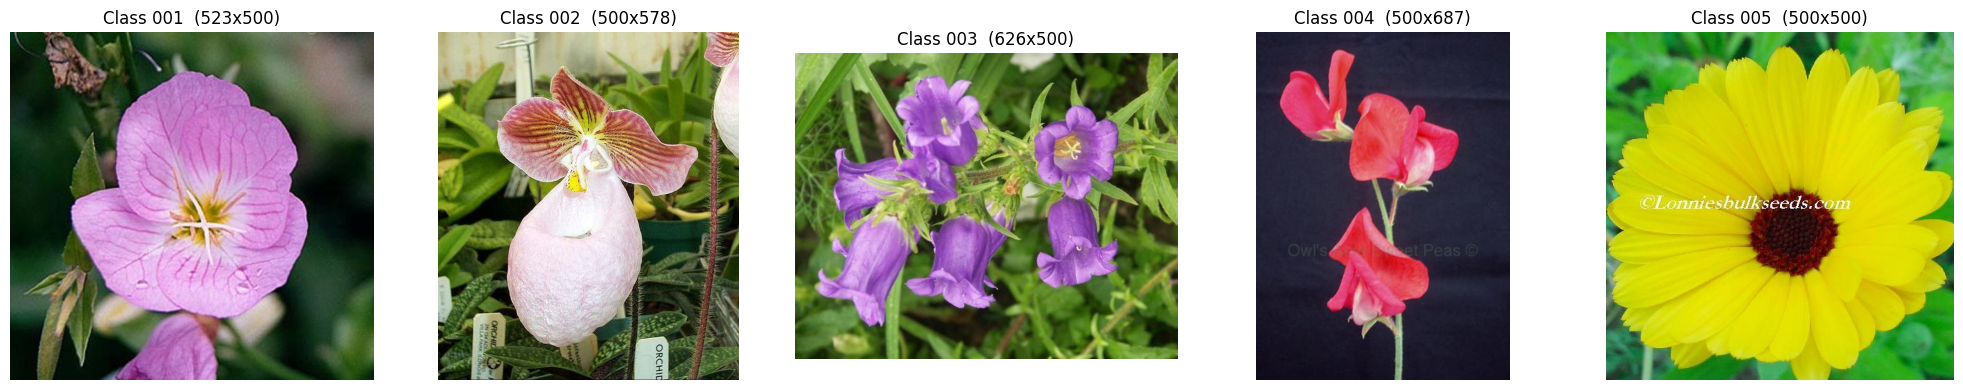

In [8]:
fig, axes = plt.subplots(1, len(class_dirs), figsize=(4 * len(class_dirs), 4))
axes = np.atleast_1d(axes)

for ax, c in zip(axes, class_dirs):
    # 1) take the first file name inside the class folder c
    # 2) open the image and convert it to RGB
    # 3) ax.imshow(...), set a title (class name + image size) and ax.axis("off")
    # WRITE YOUR CODE HERE
    classFolder = os.path.join(FLOWERS_DIR, c)
    firstFile = [f for f in sorted(os.listdir(classFolder)) if f.lower().endswith((".jpg", ".jpeg", ".png"))][0]
    sampleImg = Image.open(os.path.join(classFolder, firstFile)).convert("RGB")
    imgWidth, imgHeight = sampleImg.size
    ax.imshow(sampleImg)
    ax.set_title(f"{c.replace('flower_class_', 'Class ')}  ({imgWidth}x{imgHeight})")
    ax.axis("off")
    pass

plt.tight_layout(); plt.show()

# Step 4: Preprocessing, Augmentation and Data Split

### Why preprocessing?
```text
Original image -> Resize (224x224) -> Augmentation (train only) -> ToTensor -> Normalize (ImageNet mean/std) -> Model
```
* **Resize:** a CNN with a fixed classifier needs a fixed input size (224x224 for ResNet).
* **Augmentation:** random flips/rotations/colour changes create "new" images every epoch. This is the most important regulariser for small datasets. **Never augment validation/test images**, otherwise evaluation becomes noisy.
* **Normalization:** pretrained weights were learned with ImageNet-normalized inputs, so we must use the same mean/std.

### Data split (stratified)
```text
70% Training   -> the model learns from it
15% Validation -> monitor overfitting, pick the best epoch / hyper-parameters
15% Test       -> used ONCE at the end for the final, unbiased score
```
*Stratified* means every class keeps the same proportion in each subset.

### Task 3 — Build the transformation pipelines (Step 4)
Complete `train_tf` with **four** parts, in this order, and `eval_tf` **without augmentation**:

| Part | Transform | Notes |
|---|---|---|
| 1 | Resize | to `(IMG_SIZE, IMG_SIZE)` |
| 2 | Augmentation | random horizontal flip, random rotation (15 degrees), colour jitter (brightness/contrast/saturation 0.2) |
| 3 | Tensor | `transforms.ToTensor()` |
| 4 | Normalize | with `IMAGENET_MEAN`, `IMAGENET_STD` |

*Question to think about:* why must `eval_tf` not contain random augmentation?**Validation and test must measure the model on the real images, the same way every time. Random flips and rotations would make the scores noisy, and results couldn't be compared between epochs.**

In [9]:
IMG_SIZE = 224

train_tf = transforms.Compose([
    # (1) Resize
    # WRITE YOUR CODE HERE
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # (2) Augmentation
    # WRITE YOUR CODE HERE
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    # (3) Convert to tensor
    # WRITE YOUR CODE HERE
    transforms.ToTensor(),

    # (4) Normalize
    # WRITE YOUR CODE HERE
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Evaluation transform: resize + tensor + normalize (NO augmentation)
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),  # WRITE YOUR CODE HERE
                              transforms.ToTensor(),
                              transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])

### Task 4 — Stratified 70/15/15 split and DataLoaders (Step 4)
The two `ImageFolder` objects point to the **same files**: one applies augmentation (`train_tf`), the other does not (`eval_tf`). Complete the following:

* **(4a)** Split the **indices** with `train_test_split` (called twice): 70% train / 30% temp, then split temp 50/50 into validation and test. Use `stratify=` and `random_state=SEED` so every class keeps its proportion.
* **(4b)** Create the four `Subset` objects: `train_ds` (augmented), `train_eval_ds` (train indices but *without* augmentation, used only to measure training accuracy), `val_ds`, `test_ds`.
* **(4c)** Create the four `DataLoader`s (`BATCH = 16`): `train_loader` (shuffle=True), `train_eval_loader`, `val_loader`, `test_loader` (shuffle=False, `num_workers=2`).
* Print the size of each subset.

In [10]:
full_train = datasets.ImageFolder(FLOWERS_DIR, transform=train_tf)   # with augmentation
full_eval  = datasets.ImageFolder(FLOWERS_DIR, transform=eval_tf)    # without augmentation
class_names = full_train.classes
num_classes = len(class_names)
targets     = np.array(full_train.targets)
all_idx     = np.arange(len(targets))
print("Classes:", class_names)

# (4a) train_idx, val_idx, test_idx  (stratified 70/15/15)
# WRITE YOUR CODE HERE
# keep 70% for training, the other 30% is split again below
train_idx, holdIdx = train_test_split(all_idx, train_size=0.70, stratify=targets,
                                      shuffle=True, random_state=SEED)
# half of the held-out part is validation, the other half is test
val_idx, test_idx = train_test_split(holdIdx, train_size=0.50, stratify=targets[holdIdx],
                                     shuffle=True, random_state=SEED)

# (4b) train_ds, train_eval_ds, val_ds, test_ds
# WRITE YOUR CODE HERE
train_ds = Subset(full_train, train_idx)
train_eval_ds = Subset(full_eval, train_idx)   # same training images but no random changes
val_ds = Subset(full_eval, val_idx)
test_ds = Subset(full_eval, test_idx)

# (4c) train_loader, train_eval_loader, val_loader, test_loader
BATCH = 16
# WRITE YOUR CODE HERE
loaderSettings = {"batch_size": BATCH, "num_workers": 2}
train_loader = DataLoader(train_ds, shuffle=True, **loaderSettings)
train_eval_loader = DataLoader(train_eval_ds, shuffle=False, **loaderSettings)
val_loader = DataLoader(val_ds, shuffle=False, **loaderSettings)
test_loader = DataLoader(test_ds, shuffle=False, **loaderSettings)

# print the size of train / validation / test
# WRITE YOUR CODE HERE
for splitName, splitSet in [("Train", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
    print(f"{splitName:<10}: {len(splitSet)} images")

Classes: ['flower_class_001', 'flower_class_002', 'flower_class_003', 'flower_class_004', 'flower_class_005']
Train     : 140 images
Validation: 30 images
Test      : 30 images


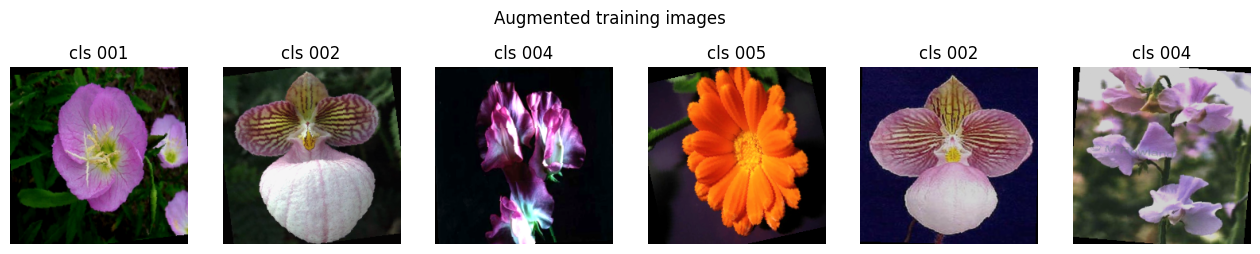

In [11]:
# ---- Visualize augmented training samples ----
MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD_T  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    # Undo ImageNet normalization so that a tensor can be displayed.
    return (t.cpu() * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, im, lb in zip(axes, imgs[:6], labels[:6]):
    ax.imshow(denorm(im)); ax.set_title(class_names[lb].replace("flower_class_", "cls ")); ax.axis("off")
plt.suptitle("Augmented training images"); plt.show()

# Step 5: ResNet-50 Architecture and Pretrained Model

### Why residual connections?
Very deep plain CNNs become *harder* to train (vanishing gradients, the "degradation problem"). ResNet adds a **skip (identity) connection** so each block learns a *residual* `F(x)` and outputs `F(x) + x`. Gradients flow directly through the shortcut, which makes networks with 50, 101 or 152 layers trainable.

### ResNet-50 overview
```text
Input 224x224x3
   |
7x7 Conv, stride 2 + BatchNorm + ReLU + 3x3 MaxPool
   |
layer1 : 3  bottleneck blocks   (256  channels)
layer2 : 4  bottleneck blocks   (512  channels)
layer3 : 6  bottleneck blocks   (1024 channels)
layer4 : 3  bottleneck blocks   (2048 channels)
   |
Global Average Pooling
   |
Fully connected (fc): 2048 -> 1000 (ImageNet)   <-- we REPLACE this layer
```

### Bottleneck residual block (used by ResNet-50)
```text
x ──────────────────────────────┐   (skip connection; 1x1 conv if shape changes)
│                               │
1x1 Conv (reduce channels) + BN + ReLU
│                               │
3x3 Conv                    + BN + ReLU
│                               │
1x1 Conv (expand channels) + BN
│                               │
└──────────── (+) Addition ◄────┘
               │
              ReLU
```
The 1x1 convolutions reduce and then restore the number of channels, so the expensive 3x3 convolution works on fewer channels (this is the "bottleneck").

### Fine-tuning strategy (2 phases)
```text
ImageNet-pretrained ResNet-50
        |
Replace fc layer (1000 -> number of flower classes)
        |
PHASE 1 - Feature extraction: freeze the whole backbone, train only fc   (lr = 1e-3)
        |
PHASE 2 - Fine-tuning: unfreeze layer4 (+ fc), continue with a smaller lr (lr = 1e-4)
        |
Final model
```
Early layers learn *generic* features (edges, colours, textures); the last layers learn *task-specific* features. Therefore we adapt the last layers first and keep the early ones.

### Task 5 — Modify the ResNet-50 classifier (Step 5)
The pretrained model has a final fully-connected layer `fc` with **1000 outputs** (ImageNet classes). Replace it so that the network predicts **your** `num_classes` flower classes.

1. Read the number of input features of the old layer (`resnet.fc.in_features`).
2. Assign a new `nn.Linear(in_features, num_classes)` to `resnet.fc`.

In [12]:
# Load ResNet-50 pretrained on ImageNet (given)
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
print("Original classifier:", resnet.fc)

# Find the number of input features of the old classifier
in_features = resnet.fc.in_features   # WRITE YOUR CODE HERE

# Replace the final layer
# WRITE YOUR CODE HERE
resnet.fc = nn.Linear(in_features=in_features, out_features=num_classes)

resnet = resnet.to(device)
print("New classifier     :", resnet.fc)

def count_params(model):
    # Return (total parameters, trainable parameters).
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, train

print("Total / trainable parameters:", count_params(resnet))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]


Original classifier: Linear(in_features=2048, out_features=1000, bias=True)
New classifier     : Linear(in_features=2048, out_features=5, bias=True)
Total / trainable parameters: (23518277, 23518277)


# Step 6: Training Utilities
We write the training code **once** and reuse it for both phases.

* `run_epoch_cls` - one pass over a loader. If an optimizer is given it trains, otherwise it evaluates (no gradients).
* `keep_frozen_bn_eval` - **important detail:** `model.train()` also updates the running mean/variance of **BatchNorm** layers, even when their weights are frozen. With a tiny dataset this would corrupt the pretrained statistics, so we keep frozen BatchNorm layers in evaluation mode.
* `fit_cls` - trains for several epochs, records the history and **saves the best model** (highest validation accuracy) to Google Drive.

In [13]:
def keep_frozen_bn_eval(model):
    # Put BatchNorm layers whose parameters are frozen into eval mode (given).
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

### Task 6 — Write the training function `run_epoch_cls` (Step 6)
The function performs **one epoch** over a loader. If an `optimizer` is passed it **trains**, otherwise it only **evaluates**. Inside the loop implement:

1. Move `images` and `labels` to `device`.
2. Forward pass: `outputs = model(images)`.
3. Compute `loss = criterion(outputs, labels)`.
4. **If training:** `optimizer.zero_grad()` -> `loss.backward()` -> `optimizer.step()`.
5. Accumulate `total_loss` (loss x batch size), `correct` (number of correct predictions, use `outputs.argmax(1)`) and `n` (number of samples).

Also define `criterion` (the loss for multi-class classification).

In [14]:
def run_epoch_cls(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)                  # train mode or eval mode
    if training:
        keep_frozen_bn_eval(model)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training): # gradients only while training
        for images, labels in loader:
            # steps 1-5 here
            # WRITE YOUR CODE HERE
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batchCount = labels.size(0)
            predictedLabels = outputs.argmax(1)
            total_loss += loss.item() * batchCount
            correct += (predictedLabels == labels).sum().item()
            n += batchCount
            pass

    return total_loss / n, correct / n

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()   # WRITE YOUR CODE HERE

In [15]:
# Given: training manager that records the history and saves the BEST model on Google Drive
cls_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
cls_phase_end = []

def fit_cls(model, optimizer, epochs, ckpt_path, scheduler=None):
    best_acc = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch_cls(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch_cls(model, val_loader, criterion)
        if scheduler: scheduler.step()
        for k, v in zip(cls_history, [tr_loss, va_loss, tr_acc, va_acc]):
            cls_history[k].append(v)
        if va_acc >= best_acc:
            best_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)
        print(f"Epoch {ep:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.3f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))   # restore best weights
    cls_phase_end.append(len(cls_history["val_acc"]))
    return best_acc

# Step 7: Phase 1 - Feature Extraction (Frozen Backbone)
We **freeze** every pretrained layer (`requires_grad = False`) and train only the new `fc` layer. The optimizer receives only the trainable parameters. We use `AdamW` with a relatively large learning rate (1e-3) because the new layer is randomly initialized.

### Task 7 — Phase 1: freeze the backbone and train the classifier (Step 7)
* **(7a)** Freeze **all** parameters of `resnet` (`requires_grad = False`), then unfreeze only `resnet.fc`.
* **(7b)** Create the optimizer `optim.AdamW` that receives **only trainable parameters** (`filter(lambda p: p.requires_grad, ...)`), `lr=1e-3`, `weight_decay=1e-4`.
* Run the training (given). Record the number of trainable parameters.

**Report:** trainable parameters in Phase 1 = 10245 ; best validation accuracy = 0.967

In [16]:
# (7a) freeze the backbone, keep only the new classifier trainable
# WRITE YOUR CODE HERE
resnet.requires_grad_(False)      # nothing in the network learns ...
resnet.fc.requires_grad_(True)    # ... except the new classifier

total, trainable = count_params(resnet)
print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")

# (7b) optimizer
optimizer = optim.AdamW([p for p in resnet.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)   # WRITE YOUR CODE HERE

# Training (given)
phase1_best = fit_cls(resnet, optimizer, epochs=10, ckpt_path=os.path.join(CKPT_DIR, "resnet50_phase1.pth"))
print(f"Best validation accuracy after Phase 1: {phase1_best:.3f}")

Phase 1 -> trainable parameters: 10,245 of 23,518,277
Epoch 01/10 | train loss 1.5093 acc 0.300 | val loss 1.3114 acc 0.633 | 38.7s
Epoch 02/10 | train loss 1.1940 acc 0.864 | val loss 1.1053 acc 0.833 | 2.2s
Epoch 03/10 | train loss 0.9906 acc 0.879 | val loss 0.9497 acc 0.900 | 2.2s
Epoch 04/10 | train loss 0.8411 acc 0.929 | val loss 0.8282 acc 0.933 | 2.2s
Epoch 05/10 | train loss 0.7074 acc 0.950 | val loss 0.7336 acc 0.933 | 2.2s
Epoch 06/10 | train loss 0.6154 acc 0.929 | val loss 0.6602 acc 0.967 | 2.3s
Epoch 07/10 | train loss 0.5436 acc 0.943 | val loss 0.5999 acc 0.933 | 1.9s
Epoch 08/10 | train loss 0.4741 acc 0.964 | val loss 0.5551 acc 0.933 | 1.9s
Epoch 09/10 | train loss 0.4355 acc 0.943 | val loss 0.5162 acc 0.933 | 1.9s
Epoch 10/10 | train loss 0.4074 acc 0.957 | val loss 0.4823 acc 0.933 | 1.9s
Best validation accuracy after Phase 1: 0.967


# Step 8: Phase 2 - Fine-Tuning (Unfreeze `layer4`)
Now we also **unfreeze `layer4`** (the deepest, most task-specific block) and train it together with `fc`. The learning rate is **10x smaller (1e-4)** so that the pretrained weights are adjusted gently and not destroyed. A cosine scheduler lowers the learning rate smoothly during training.

### Task 8 — Phase 2: fine-tune `layer4` (Step 8)
* **(8a)** Unfreeze the last residual stage `resnet.layer4`.
* **(8b)** Create a **new** `AdamW` optimizer with a **smaller learning rate (1e-4)** over the trainable parameters.

**Report:** trainable parameters in Phase 2 = 14,974,981 ; best validation accuracy = 0.967 ; did fine-tuning help?
**Answer::** Yes, but not in accuracy. Peak validation accuracy stayed at 0.967. Validation loss fell from 0.48 to 0.16, training accuracy rose from 0.957 to 0.993, and test accuracy reached 1.000. So the model became more confident and more accurate on the test set.

In [17]:
# (8a) unfreeze layer4
# WRITE YOUR CODE HERE
resnet.layer4.requires_grad_(True)

total, trainable = count_params(resnet)
print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")

# (8b) new optimizer with a smaller learning rate
optimizer = optim.AdamW([p for p in resnet.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)   # WRITE YOUR CODE HERE

# Scheduler + training (given)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
phase2_best = fit_cls(resnet, optimizer, epochs=10, ckpt_path=os.path.join(CKPT_DIR, "resnet50_best.pth"), scheduler=scheduler)
print(f"Best validation accuracy after Phase 2: {phase2_best:.3f}")

Phase 2 -> trainable parameters: 14,974,981 of 23,518,277
Epoch 01/10 | train loss 0.8719 acc 0.657 | val loss 0.4863 acc 0.933 | 6.4s
Epoch 02/10 | train loss 0.5036 acc 0.893 | val loss 0.3365 acc 0.933 | 2.4s
Epoch 03/10 | train loss 0.2838 acc 0.979 | val loss 0.2627 acc 0.967 | 2.3s
Epoch 04/10 | train loss 0.1638 acc 0.986 | val loss 0.2005 acc 0.967 | 2.3s
Epoch 05/10 | train loss 0.1051 acc 0.986 | val loss 0.1886 acc 0.967 | 2.4s
Epoch 06/10 | train loss 0.1113 acc 0.971 | val loss 0.1732 acc 0.967 | 2.3s
Epoch 07/10 | train loss 0.0697 acc 0.993 | val loss 0.1654 acc 0.967 | 2.3s
Epoch 08/10 | train loss 0.0531 acc 0.993 | val loss 0.1622 acc 0.967 | 2.3s
Epoch 09/10 | train loss 0.0808 acc 0.986 | val loss 0.1649 acc 0.967 | 2.4s
Epoch 10/10 | train loss 0.0475 acc 0.993 | val loss 0.1614 acc 0.967 | 2.3s
Best validation accuracy after Phase 2: 0.967


# Step 9: Training Curves
Curves reveal overfitting: if training accuracy keeps rising while validation accuracy stagnates or falls (and validation loss rises), the model memorizes the training set. The dashed line marks the start of Phase 2.

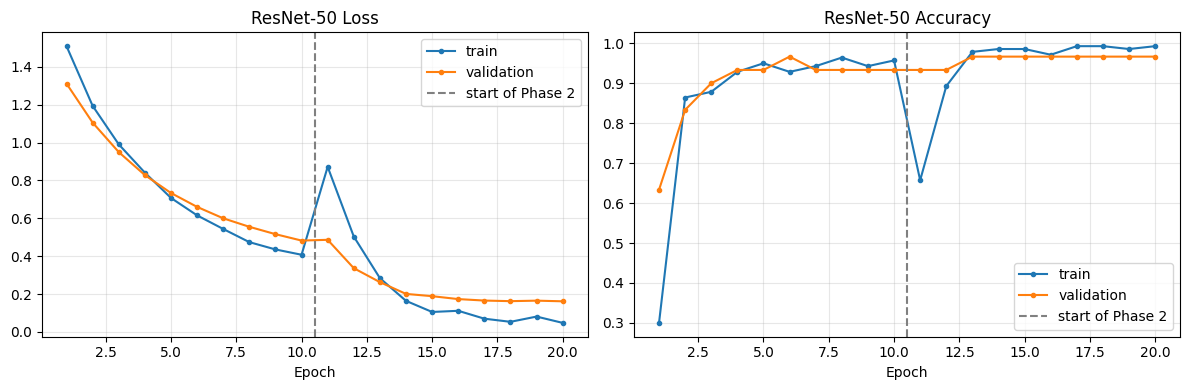

In [18]:
def plot_history(hist, phase_end, keys, titles, save_path):
    # Plot train/val curves for each metric pair with a line where Phase 2 starts.
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 4))
    axes = np.atleast_1d(axes)
    for ax, (tr, va), title in zip(axes, keys, titles):
        ax.plot(range(1, len(hist[tr]) + 1), hist[tr], label="train", marker="o", ms=3)
        ax.plot(range(1, len(hist[va]) + 1), hist[va], label="validation", marker="o", ms=3)
        if len(phase_end) > 1:
            ax.axvline(phase_end[0] + 0.5, color="gray", ls="--", label="start of Phase 2")
        ax.set_xlabel("Epoch"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.show()

plot_history(cls_history, cls_phase_end,
             keys=[("train_loss", "val_loss"), ("train_acc", "val_acc")],
             titles=["ResNet-50 Loss", "ResNet-50 Accuracy"],
             save_path=os.path.join(RESULTS_DIR, "resnet_results.png"))

# Step 10: Evaluation on the Test Set
We now evaluate the best model on the **test set**, which was never used for training or model selection. Metrics:

* **Accuracy** = correct predictions / all predictions.
* **Precision** = of the images predicted as class *c*, how many really are *c*.
* **Recall** = of all images of class *c*, how many were found.
* **F1-score** = harmonic mean of precision and recall.
* **Confusion matrix** = rows are true classes, columns are predicted classes; off-diagonal cells are mistakes.

### Task 9 — Test-set predictions and metrics (Step 10)
* **(9a)** Complete `predict_loader`: for every batch run the model, take `argmax(1)` as the prediction and store true and predicted labels.
* **(9b)** Compute `resnet_train_acc`, `resnet_val_acc`, `resnet_test_acc` (use `accuracy_score`) and the **macro** `resnet_prec`, `resnet_rec`, `resnet_f1` on the **test set** (`precision_recall_fscore_support(..., average="macro")`).
* **(9c)** Print the `classification_report` of the test set.

In [19]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        # forward pass, argmax, append to y_true / y_pred
        # WRITE YOUR CODE HERE
        batchPreds = model(images.to(device)).argmax(1)
        y_true += labels.tolist()
        y_pred += batchPreds.cpu().tolist()
        pass
    return np.array(y_true), np.array(y_pred)

yt_tr, yp_tr = predict_loader(resnet, train_eval_loader)
yt_va, yp_va = predict_loader(resnet, val_loader)
yt_te, yp_te = predict_loader(resnet, test_loader)

# (9b) accuracies and macro precision / recall / F1
resnet_train_acc = resnet_val_acc = resnet_test_acc = None
resnet_prec = resnet_rec = resnet_f1 = None
# WRITE YOUR CODE HERE
resnet_train_acc = accuracy_score(yt_tr, yp_tr)
resnet_val_acc = accuracy_score(yt_va, yp_va)
resnet_test_acc = accuracy_score(yt_te, yp_te)
resnet_prec, resnet_rec, resnet_f1, _ = precision_recall_fscore_support(
    yt_te, yp_te, average="macro", zero_division=0)

scoreTable = {"Train accuracy": resnet_train_acc, "Validation accuracy": resnet_val_acc,
              "Test accuracy": resnet_test_acc, "Precision (macro)": resnet_prec,
              "Recall (macro)": resnet_rec, "F1-score (macro)": resnet_f1}
for metricName, metricValue in scoreTable.items():
    print(f"{metricName:<20} {metricValue:.3f}")

# (9c) classification report
# WRITE YOUR CODE HERE
print("\nClassification report (test set)")
print(classification_report(yt_te, yp_te, labels=list(range(num_classes)),
                            target_names=class_names, digits=3, zero_division=0))

Train accuracy       1.000
Validation accuracy  0.967
Test accuracy        1.000
Precision (macro)    1.000
Recall (macro)       1.000
F1-score (macro)     1.000

Classification report (test set)
                  precision    recall  f1-score   support

flower_class_001      1.000     1.000     1.000         6
flower_class_002      1.000     1.000     1.000         6
flower_class_003      1.000     1.000     1.000         6
flower_class_004      1.000     1.000     1.000         6
flower_class_005      1.000     1.000     1.000         6

        accuracy                          1.000        30
       macro avg      1.000     1.000     1.000        30
    weighted avg      1.000     1.000     1.000        30



### Task 10 — Confusion matrix and hardest class (Step 10)
1. Compute the confusion matrix `cm` of the test set (`confusion_matrix`).
2. Display it with `ConfusionMatrixDisplay` and save the figure as `results/resnet_confusion_matrix.png` (`plt.savefig(os.path.join(RESULTS_DIR, ...))`).
3. Compute the **accuracy of each class** (diagonal / row sum) and store the name of the worst class in `hardest_class`.

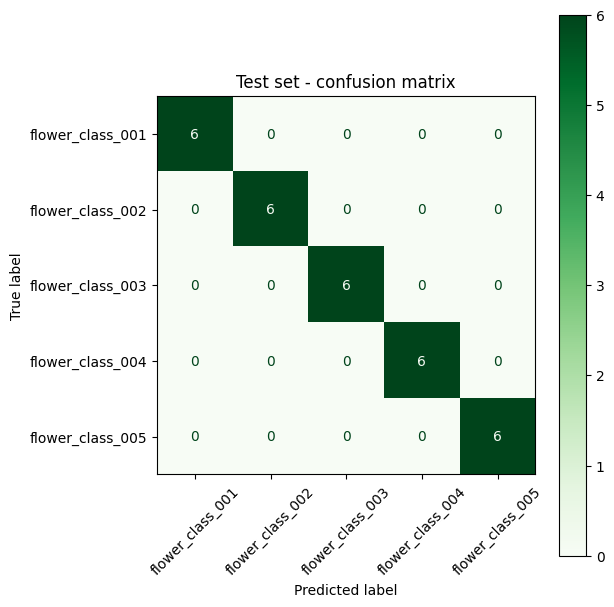

    flower_class_001: 100.00%
    flower_class_002: 100.00%
    flower_class_003: 100.00%
    flower_class_004: 100.00%
    flower_class_005: 100.00%
Hardest class -> flower_class_001


In [20]:
# WRITE YOUR CODE HERE
testMatrix = confusion_matrix(yt_te, yp_te, labels=list(range(num_classes)))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
cmPlot = ConfusionMatrixDisplay(confusion_matrix=testMatrix, display_labels=class_names)
cmPlot.plot(ax=ax, cmap="Greens", xticks_rotation=45, colorbar=True, values_format="d")
ax.set_title("Test set - confusion matrix")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "resnet_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

# accuracy of a class = correct ones (diagonal) / all images of that class (row total)
classAccuracy = {}
for row, className in enumerate(class_names):
    rowTotal = testMatrix[row].sum()
    classAccuracy[className] = testMatrix[row, row] / rowTotal if rowTotal > 0 else 0.0
    print(f"{className:>20}: {classAccuracy[className]:.2%}")

lowestClass = min(classAccuracy, key=classAccuracy.get)
print("Hardest class ->", lowestClass)
cm = testMatrix
hardest_class = lowestClass

### Task 11 — Look at the mistakes (Step 10)
Find the indices where `yt_te != yp_te` and show up to **6 misclassified test images** with their true and predicted class. *Hint:* use `test_ds[i]` to get an image and the `denorm()` helper to display it.

**Observation:** why might the model confuse these images? No test images were misclassified. **The 5 flower classes look very different in colour and shape, so the pretrained features separate them easily. With only 6 test images per class, though, the 100% score may not hold on a larger test set.**

In [21]:
# WRITE YOUR CODE HERE
mistakeIdx = [i for i in range(len(yt_te)) if yt_te[i] != yp_te[i]]
print(f"{len(mistakeIdx)} of {len(yt_te)} test images were misclassified")

if mistakeIdx:
    toShow = mistakeIdx[:6]
    fig, axes = plt.subplots(1, len(toShow), figsize=(3.2 * len(toShow), 3.8), squeeze=False)
    for ax, i in zip(axes[0], toShow):
        wrongImg, _ = test_ds[i]        # test_loader keeps the order, so i lines up
        ax.imshow(denorm(wrongImg))
        ax.set_title(f"actual: {class_names[yt_te[i]]}\npredicted: {class_names[yp_te[i]]}",
                     fontsize=8, color="darkred")
        ax.axis("off")
    plt.suptitle("Misclassified test images")
    plt.tight_layout()
    plt.show()

0 of 30 test images were misclassified


---
# PART B - U-Net Fine-Tuning (Segmentation)
---
# Step 11: Explore the Pet Segmentation Dataset
Segmentation assigns a label to **every pixel**. Each training example consists of:
```text
Image (RGB)  +  Ground-truth mask (same height/width)
```
The original masks are *trimaps*: `1 = pet`, `2 = background`, `3 = border`. We convert them to a **binary mask**: `pet (1 and 3) -> 1`, `background (2) -> 0`. First we verify that every image has a mask.

### Task 12 — Verify the image/mask pairs (Step 11)
* **(12a)** Fill `img_files` and `mask_files`: dictionaries mapping the **file-name stem** (name without extension, `os.path.splitext`) to the file name.
* **(12b)** Compute `pair_stems` = sorted list of stems present in **both** dictionaries and print: number of images, number of masks, number of valid pairs.
* **(12c)** Display **4 samples** (image on top, binary mask below). The function `load_binary_mask` is given.

**Report:** images = 120 , masks = 120 , valid pairs = 120

Images      : 150
Masks       : 150
Valid pairs : 150


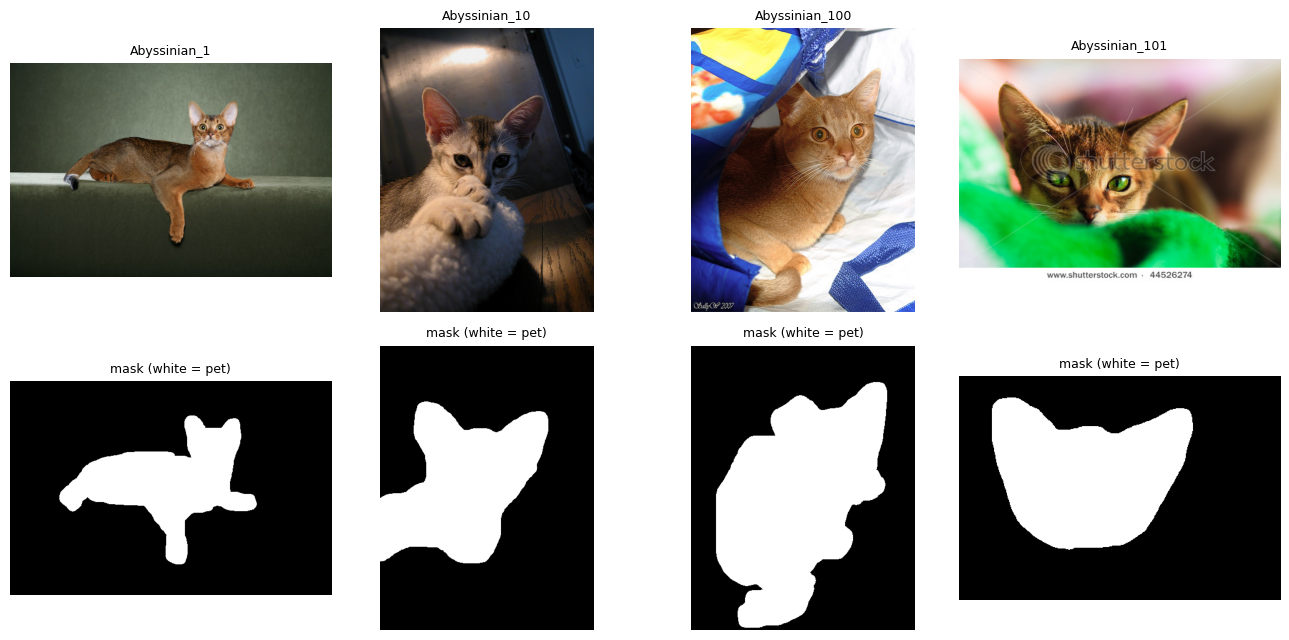

In [22]:
# (12a) dictionaries stem -> file name
img_files, mask_files = {}, {}
# WRITE YOUR CODE HERE
for fileName in os.listdir(PET_IMG_DIR):
    fileStem, fileExt = os.path.splitext(fileName)
    if fileExt.lower() in (".jpg", ".jpeg", ".png"):
        img_files[fileStem] = fileName

for fileName in os.listdir(PET_MASK_DIR):
    fileStem, fileExt = os.path.splitext(fileName)
    if fileExt.lower() == ".png":
        mask_files[fileStem] = fileName

# (12b) pairs and printing
pair_stems = []
# WRITE YOUR CODE HERE
pair_stems = sorted(set(img_files) & set(mask_files))   # stems that have BOTH an image and a mask

print("Images      :", len(img_files))
print("Masks       :", len(mask_files))
print("Valid pairs :", len(pair_stems))

def load_binary_mask(path):
    # Read a trimap and convert it to a binary mask (255 = pet, 0 = background). (given)
    arr = np.array(Image.open(path).convert("L"))
    return Image.fromarray((((arr == 1) | (arr == 3)) * 255).astype(np.uint8))

# (12c) visualize 4 image/mask samples (2 rows x 4 columns)
# WRITE YOUR CODE HERE
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, stem in enumerate(pair_stems[:4]):
    petImg = Image.open(os.path.join(PET_IMG_DIR, img_files[stem])).convert("RGB")
    petMask = load_binary_mask(os.path.join(PET_MASK_DIR, mask_files[stem]))
    axes[0][col].imshow(petImg)
    axes[0][col].set_title(stem, fontsize=9)
    axes[1][col].imshow(petMask, cmap="gray")
    axes[1][col].set_title("mask (white = pet)", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Step 12: Joint Image/Mask Preprocessing, Split and Loaders
> **Golden rule:** every *spatial* transformation (resize, flip, rotation) must be applied **identically** to the image **and** its mask:
> ```text
> Image ── Horizontal Flip ──► Augmented Image
> Mask  ── Horizontal Flip ──► Augmented Mask
> ```
Additional rules used below:
* Masks are resized/rotated with **nearest-neighbour** interpolation so values stay 0 or 1 (no blurred labels).
* Colour changes and normalization are applied to the **image only**.
* Images are resized to **256x256** (U-Net needs sizes divisible by 32).

### Task 13 — Segmentation dataset with joint transforms (Step 12)
Complete `__getitem__` of `PetSegDataset`. Remember the **golden rule**: *the same spatial transformation must be applied to the image and its mask.*

1. **Resize** both to `size x size` — the mask with `interpolation=TF.InterpolationMode.NEAREST`.
2. **If `self.train`:** random horizontal flip (probability 0.5, **same decision** for image and mask); random rotation by the **same angle** (use `TF.rotate`, mask with NEAREST); brightness/contrast change on the **image only**.
3. Image: `TF.to_tensor` then `TF.normalize(..., IMAGENET_MEAN, IMAGENET_STD)`. Mask: `TF.to_tensor` and convert to binary float `(mask > 0.5).float()`.

*Question:* why is NEAREST interpolation used for masks?**Masks hold class labels, 0 or 1. Bilinear interpolation would blend them into in-between values like 0.5 at the edges, which aren't valid labels. NEAREST keeps every pixel exactly 0 or 1.**

In [23]:
SEG_SIZE = 256

class PetSegDataset(Dataset):
    def __init__(self, stems, train=False, size=SEG_SIZE):
        self.stems, self.train, self.size = stems, train, size

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, i):
        s = self.stems[i]
        image = Image.open(os.path.join(PET_IMG_DIR, img_files[s])).convert("RGB")
        mask  = load_binary_mask(os.path.join(PET_MASK_DIR, mask_files[s]))   # binary mask

        # Step 1: resize
        # WRITE YOUR CODE HERE
        newSize = [self.size, self.size]
        image = TF.resize(image, newSize)
        mask = TF.resize(mask, newSize, interpolation=TF.InterpolationMode.NEAREST)

        # Step 2: augmentation (only when self.train is True)
        # WRITE YOUR CODE HERE
        if self.train:
            # one coin toss decides the flip for BOTH image and mask
            if torch.rand(1).item() < 0.5:
                image, mask = TF.hflip(image), TF.hflip(mask)

            # one random angle used for BOTH image and mask
            rotAngle = random.randint(-20, 20)
            image = TF.rotate(image, rotAngle, interpolation=TF.InterpolationMode.BILINEAR)
            mask = TF.rotate(mask, rotAngle, interpolation=TF.InterpolationMode.NEAREST)

            # colour changes only make sense for the image
            image = TF.adjust_brightness(image, random.uniform(0.85, 1.15))
            image = TF.adjust_contrast(image, random.uniform(0.9, 1.1))

        # Step 3: tensor + normalize (image), tensor + binarize (mask)
        # WRITE YOUR CODE HERE
        image = TF.normalize(TF.to_tensor(image), IMAGENET_MEAN, IMAGENET_STD)
        mask = (TF.to_tensor(mask) > 0.5).float()

        return image, mask

### Task 14 — Split and DataLoaders for segmentation (Step 12)
Shuffle `stems` (already done, reproducible) and split **70/15/15**. Create `seg_train_ds` (with `train=True`), `seg_val_ds`, `seg_test_ds`, then the three loaders `seg_train_loader` (shuffle), `seg_val_loader`, `seg_test_loader` with `SEG_BATCH = 8`. Print the size of each subset.

In [24]:
stems = list(pair_stems)
random.Random(SEED).shuffle(stems)

# 70 / 15 / 15 split and datasets
# WRITE YOUR CODE HERE
valCount = round(0.15 * len(stems))
testCount = round(0.15 * len(stems))
testStems = stems[:testCount]
valStems = stems[testCount:testCount + valCount]
trainStems = stems[testCount + valCount:]          # whatever is left (~70%)

seg_train_ds = PetSegDataset(trainStems, train=True)
seg_val_ds = PetSegDataset(valStems)
seg_test_ds = PetSegDataset(testStems)

SEG_BATCH = 8
# DataLoaders
# WRITE YOUR CODE HERE
seg_train_loader = DataLoader(seg_train_ds, batch_size=SEG_BATCH, shuffle=True)
seg_val_loader = DataLoader(seg_val_ds, batch_size=SEG_BATCH)
seg_test_loader = DataLoader(seg_test_ds, batch_size=SEG_BATCH)

print(f"Train {len(seg_train_ds)} | Validation {len(seg_val_ds)} | Test {len(seg_test_ds)}")

Train 106 | Validation 22 | Test 22


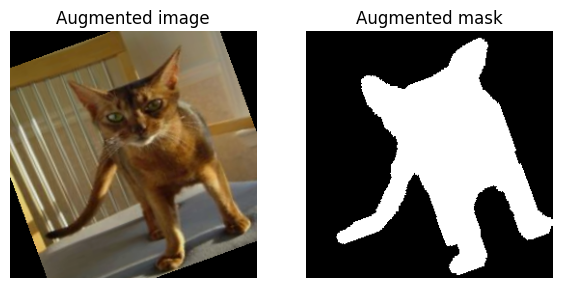

In [25]:
# Given: check that the image and mask are still aligned after augmentation
im, mk = seg_train_ds[0]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(denorm(im)); ax[0].set_title("Augmented image"); ax[0].axis("off")
ax[1].imshow(mk[0], cmap="gray"); ax[1].set_title("Augmented mask"); ax[1].axis("off")
plt.show()

# Step 13: U-Net Architecture and Model Creation
U-Net is an **encoder-decoder** network designed for pixel-wise prediction.

```text
                         U-NET (ResNet-50 encoder)

Input Image (256x256x3)
     │
     ▼
┌─────────────┐
│ Encoder 1   │───────────────┐         Encoder  : a ResNet-50 that extracts increasingly
└─────────────┘               │                    abstract features while halving the resolution
     │                        │
     ▼                        │         Skip     : encoder feature maps are copied (concatenated)
┌─────────────┐               │         connect.   to the decoder at the SAME resolution, giving the
│ Encoder 2   │──────────┐    │                    decoder the fine spatial detail lost by pooling
└─────────────┘          │    │
     │                   │    │         Bottleneck: deepest, most abstract representation
     ▼                   │    │
┌─────────────┐          │    │         Decoder  : up-sampling + convolution blocks that
│ Encoder 3   │─────┐    │    │                    rebuild the spatial resolution step by step
└─────────────┘     │    │    │
     │              │    │    │         Head     : 1x1 conv -> 1 channel (logit per pixel)
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Bottleneck  │     │    │    │
└─────────────┘     │    │    │
     │              │    │    │
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Decoder 3   │◄────┘    │    │
└─────────────┘          │    │
     │                   │    │
     ▼                   │    │
┌─────────────┐          │    │
│ Decoder 2   │◄─────────┘    │
└─────────────┘               │
     │                        │
     ▼                        │
┌─────────────┐               │
│ Decoder 1   │◄──────────────┘
└─────────────┘
     │
     ▼
Segmentation Mask (256x256x1)
```
**Why a pretrained encoder?** With only ~100 training images, a randomly initialized encoder would overfit. The ImageNet-pretrained ResNet-50 encoder already extracts good edges/textures/shapes, so we mainly have to train the **decoder** and gently adapt the encoder.

**Fine-tuning strategy** (same idea as ResNet): Phase 1 freeze the encoder and train decoder + head; Phase 2 unfreeze the last encoder stages (`layer3`, `layer4`) with a smaller learning rate.

In [26]:
# U-Net with a pretrained ResNet-50 encoder, 1 output channel (binary mask), outputs raw logits
unet = smp.Unet(
    encoder_name="resnet50",       # ResNet-50 backbone as the encoder
    encoder_weights="imagenet",    # pretrained on ImageNet
    in_channels=3,                 # RGB
    classes=1,                     # binary segmentation: 1 logit per pixel
).to(device)

total, trainable = count_params(unet)
enc_total = sum(p.numel() for p in unet.encoder.parameters())
print(f"Total parameters: {total:,} | Encoder: {enc_total:,} | Decoder + head: {total - enc_total:,}")

# Quick shape test: input [2,3,256,256] -> output must be [2,1,256,256]
with torch.no_grad():
    print("Output shape:", unet(torch.randn(2, 3, SEG_SIZE, SEG_SIZE).to(device)).shape)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 32,521,105 | Encoder: 23,508,032 | Decoder + head: 9,013,073
Output shape: torch.Size([2, 1, 256, 256])


# Step 14: Loss Function and Metrics

### Loss = BCE + Dice
* **Binary Cross-Entropy (BCE)** treats every pixel as an independent classification problem.
* **Dice loss** `= 1 - Dice` directly optimizes the *overlap* between prediction and ground truth. It is robust to **class imbalance** (the pet may cover only a small part of the image, so "predict everything background" would give a low BCE but a bad Dice).

### Metrics
```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )

IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```
Both range from 0 (no overlap) to 1 (perfect). IoU is always <= Dice for the same prediction. Predicted probabilities are thresholded at 0.5 for the metrics.

### Task 15 — Segmentation loss and metrics (Step 14)
Implement the following functions. Inputs are **logits** (`[B,1,H,W]`) and binary `targets` of the same shape. Sum over the dimensions `(1, 2, 3)` to get one value per image, then average over the batch. Use `eps=1e-6` to avoid division by zero.

| Function | Definition | Notes |
|---|---|---|
| `dice_loss` | `1 - mean( (2*inter + eps) / (union + eps) )` | uses **probabilities** `torch.sigmoid(logits)`; `union = sum(p) + sum(target)` |
| `seg_loss` | `BCE + Dice loss` | use `bce_loss_fn` |
| `dice_score` | same formula as above | uses the **thresholded** prediction `(sigmoid > 0.5).float()`; return `.item()` |
| `iou_score` | `(inter + eps) / (union + eps)` | here `union = sum(pred) + sum(target) - inter`; return `.item()` |

```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )
IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```

In [27]:
bce_loss_fn = nn.BCEWithLogitsLoss()      # includes the sigmoid -> the model outputs logits

def dice_loss(logits, targets, eps=1e-6):
    # WRITE YOUR CODE HERE
    probMap = torch.sigmoid(logits)
    overlap = (probMap * targets).sum(dim=(1, 2, 3))
    sizeSum = probMap.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    diceEach = (2 * overlap + eps) / (sizeSum + eps)
    return 1 - diceEach.mean()
    pass

def seg_loss(logits, targets):
    # WRITE YOUR CODE HERE
    bceValue = bce_loss_fn(logits, targets)
    diceValue = dice_loss(logits, targets)
    return bceValue + diceValue
    pass

def dice_score(logits, targets, eps=1e-6):
    # WRITE YOUR CODE HERE
    binaryPred = (torch.sigmoid(logits) > 0.5).float()
    overlap = (binaryPred * targets).sum(dim=(1, 2, 3))
    sizeSum = binaryPred.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    return ((2 * overlap + eps) / (sizeSum + eps)).mean().item()
    pass

def iou_score(logits, targets, eps=1e-6):
    # WRITE YOUR CODE HERE
    binaryPred = (torch.sigmoid(logits) > 0.5).float()
    overlap = (binaryPred * targets).sum(dim=(1, 2, 3))
    unionArea = binaryPred.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) - overlap
    return ((overlap + eps) / (unionArea + eps)).mean().item()
    pass

def pixel_accuracy(logits, targets):
    # Fraction of correctly classified pixels (given)
    return ((torch.sigmoid(logits) > 0.5).float() == targets).float().mean().item()

### Task 16 — One segmentation epoch (Step 14)
Complete `run_epoch_seg`: for every batch move data to `device`, forward pass, `loss = seg_loss(logits, masks)`, **if training** `zero_grad -> backward -> step`, and accumulate the **loss, Dice and IoU** weighted by the batch size `k = images.size(0)`. Return `(avg loss, avg dice, avg iou)`.

In [28]:
def run_epoch_seg(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        keep_frozen_bn_eval(model)
    tot_loss = tot_dice = tot_iou = n = 0

    with torch.set_grad_enabled(training):
        for images, masks in loader:
            # WRITE YOUR CODE HERE
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = seg_loss(logits, masks)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batchCount = images.size(0)
            detachedLogits = logits.detach()
            tot_loss += loss.item() * batchCount
            tot_dice += dice_score(detachedLogits, masks) * batchCount
            tot_iou += iou_score(detachedLogits, masks) * batchCount
            n += batchCount
            pass

    return tot_loss / n, tot_dice / n, tot_iou / n

In [29]:
# Given: training manager (keeps the checkpoint with the best validation Dice)
seg_history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "train_iou": [], "val_iou": []}
seg_phase_end = []

def fit_seg(model, optimizer, epochs, ckpt_path, scheduler=None):
    best = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        trl, trd, tri = run_epoch_seg(model, seg_train_loader, optimizer)
        val, vad, vai = run_epoch_seg(model, seg_val_loader)
        if scheduler: scheduler.step()
        for k, v in zip(seg_history, [trl, val, trd, vad, tri, vai]):
            seg_history[k].append(v)
        if vad >= best:
            best = vad
            torch.save(model.state_dict(), ckpt_path)
        print(f"Epoch {ep:02d}/{epochs} | train loss {trl:.4f} dice {trd:.3f} | "
              f"val loss {val:.4f} dice {vad:.3f} iou {vai:.3f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    seg_phase_end.append(len(seg_history["val_dice"]))
    return best

# Step 15: Phase 1 - Train the Decoder (Frozen Encoder)
The pretrained ResNet-50 encoder is frozen; only the randomly initialized decoder and segmentation head are trained (lr = 1e-3).

### Task 17 — U-Net Phase 1: freeze the encoder (Step 15)
* **(17a)** Freeze **all** parameters of `unet.encoder`.
* **(17b)** Create `AdamW` over the trainable parameters (`lr=1e-3`, `weight_decay=1e-4`).

**Report:** trainable parameters = 9,013,073 ; best validation Dice after Phase 1 = 0.869

In [30]:
# (17a) freeze the encoder
# WRITE YOUR CODE HERE
unet.encoder.requires_grad_(False)

total, trainable = count_params(unet)
print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")

# (17b) optimizer
optimizer = optim.AdamW([p for p in unet.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)   # WRITE YOUR CODE HERE

unet_phase1_best = fit_seg(unet, optimizer, epochs=15, ckpt_path=os.path.join(CKPT_DIR, "unet_phase1.pth"))
print(f"Best validation Dice after Phase 1: {unet_phase1_best:.3f}")

Phase 1 -> trainable parameters: 9,013,073 of 32,521,105
Epoch 01/15 | train loss 0.7940 dice 0.751 | val loss 2.6036 dice 0.732 iou 0.603 | 53.1s
Epoch 02/15 | train loss 0.4078 dice 0.882 | val loss 0.5620 dice 0.834 iou 0.746 | 4.5s
Epoch 03/15 | train loss 0.3232 dice 0.905 | val loss 0.5447 dice 0.821 iou 0.729 | 4.0s
Epoch 04/15 | train loss 0.3004 dice 0.913 | val loss 0.4672 dice 0.846 iou 0.768 | 6.1s
Epoch 05/15 | train loss 0.2571 dice 0.923 | val loss 0.5161 dice 0.843 iou 0.760 | 4.0s
Epoch 06/15 | train loss 0.2812 dice 0.919 | val loss 0.4460 dice 0.852 iou 0.775 | 4.3s
Epoch 07/15 | train loss 0.2487 dice 0.925 | val loss 0.4341 dice 0.856 iou 0.781 | 4.4s
Epoch 08/15 | train loss 0.2102 dice 0.937 | val loss 0.5581 dice 0.809 iou 0.722 | 4.2s
Epoch 09/15 | train loss 0.2127 dice 0.934 | val loss 0.4812 dice 0.848 iou 0.768 | 4.1s
Epoch 10/15 | train loss 0.1930 dice 0.940 | val loss 0.4464 dice 0.854 iou 0.780 | 7.8s
Epoch 11/15 | train loss 0.1957 dice 0.940 | val los

# Step 16: Phase 2 - Fine-Tune the Encoder
We unfreeze the last two encoder stages (`layer3`, `layer4`). They get a small learning rate (1e-4); the decoder and head continue with a moderate one (3e-4). Different learning rates per parameter group are called **discriminative learning rates**.

### Task 18 — U-Net Phase 2: fine-tune the encoder (Step 16)
* **(18a)** Unfreeze `unet.encoder.layer3` and `unet.encoder.layer4`.
* **(18b)** Build an `AdamW` optimizer with **two parameter groups** (*discriminative learning rates*): the unfrozen encoder layers with `lr=1e-4`, and all the other trainable parameters (decoder + segmentation head) with `lr=3e-4`.
  *Hint:* collect the encoder parameters in a list, then take the remaining trainable parameters whose `id()` is not in the encoder list.

**Report:** best validation Dice after Phase 2 = 0.881 ; improvement over Phase 1? yes, small but yes

In [31]:
# (18a) unfreeze layer3 and layer4 of the encoder
# WRITE YOUR CODE HERE
unet.encoder.layer3.requires_grad_(True)
unet.encoder.layer4.requires_grad_(True)

# split the trainable weights into two groups for different learning rates
encoderParams = list(unet.encoder.layer3.parameters()) + list(unet.encoder.layer4.parameters())
encoderIds = {id(p) for p in encoderParams}
decoderParams = [p for p in unet.parameters() if p.requires_grad and id(p) not in encoderIds]

total, trainable = count_params(unet)
print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")

# (18b) optimizer with two parameter groups
optimizer = optim.AdamW([{"params": encoderParams, "lr": 1e-4},     # WRITE YOUR CODE HERE
                         {"params": decoderParams, "lr": 3e-4}],
                        weight_decay=1e-4)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)
unet_phase2_best = fit_seg(unet, optimizer, epochs=15, ckpt_path=os.path.join(CKPT_DIR, "unet_best.pth"), scheduler=scheduler)
print(f"Best validation Dice after Phase 2: {unet_phase2_best:.3f}")

Phase 2 -> trainable parameters: 31,076,177 of 32,521,105
Epoch 01/15 | train loss 0.2470 dice 0.928 | val loss 0.4039 dice 0.876 iou 0.812 | 11.1s
Epoch 02/15 | train loss 0.2169 dice 0.935 | val loss 0.4130 dice 0.873 iou 0.810 | 4.7s
Epoch 03/15 | train loss 0.1668 dice 0.950 | val loss 0.4645 dice 0.863 iou 0.796 | 4.6s
Epoch 04/15 | train loss 0.1482 dice 0.955 | val loss 0.4385 dice 0.865 iou 0.798 | 7.6s
Epoch 05/15 | train loss 0.1484 dice 0.954 | val loss 0.4242 dice 0.871 iou 0.807 | 4.8s
Epoch 06/15 | train loss 0.1347 dice 0.959 | val loss 0.4012 dice 0.878 iou 0.818 | 5.1s
Epoch 07/15 | train loss 0.1288 dice 0.960 | val loss 0.4035 dice 0.879 iou 0.820 | 5.2s
Epoch 08/15 | train loss 0.1289 dice 0.961 | val loss 0.4140 dice 0.879 iou 0.821 | 5.2s
Epoch 09/15 | train loss 0.1150 dice 0.964 | val loss 0.4058 dice 0.879 iou 0.821 | 5.3s
Epoch 10/15 | train loss 0.1202 dice 0.963 | val loss 0.4083 dice 0.879 iou 0.820 | 4.8s
Epoch 11/15 | train loss 0.1117 dice 0.965 | val lo

# Step 17: Evaluation and Visualization
Final evaluation on the **test set** (Dice, IoU, pixel accuracy), training curves, and a visual comparison `Input | Ground truth | Prediction | Overlay`.

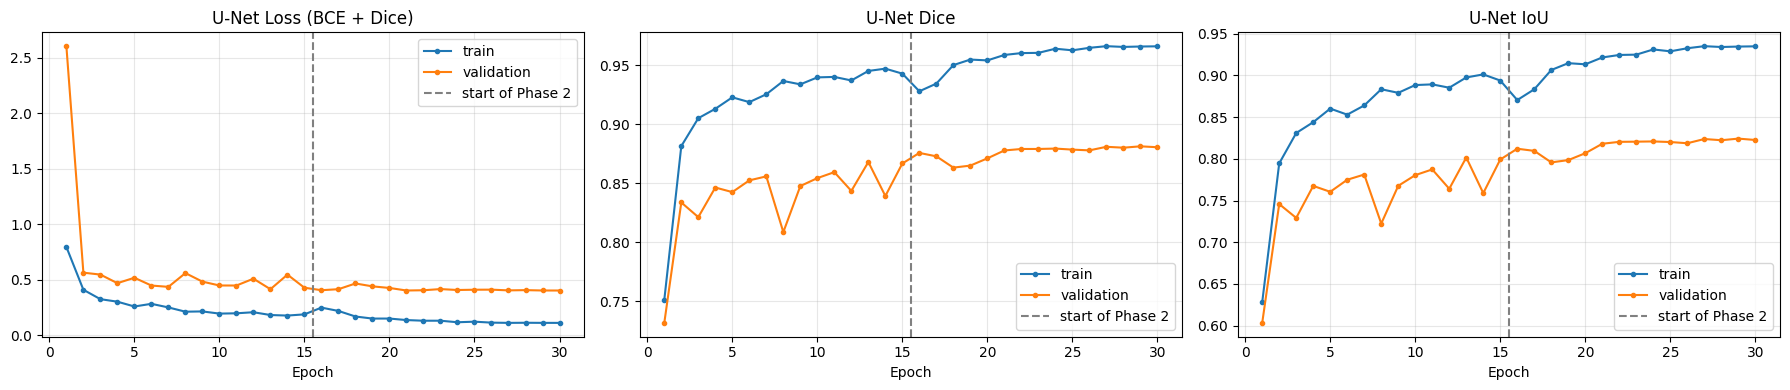

In [32]:
# Given: training curves of the U-Net
plot_history(seg_history, seg_phase_end,
             keys=[("train_loss", "val_loss"), ("train_dice", "val_dice"), ("train_iou", "val_iou")],
             titles=["U-Net Loss (BCE + Dice)", "U-Net Dice", "U-Net IoU"],
             save_path=os.path.join(RESULTS_DIR, "unet_curves.png"))

### Task 19 — Evaluate the U-Net (Step 17)
Write `evaluate_seg(model, loader)`: loop over the loader in eval mode (no gradients), accumulate `seg_loss`, `dice_score`, `iou_score` and `pixel_accuracy` (weighted by batch size) and **return** `(loss, dice, iou, pixel_acc)` averages. The calls below use it to produce the validation and test results.

In [33]:
@torch.no_grad()
def evaluate_seg(model, loader):
    model.eval()
    # WRITE YOUR CODE HERE
    sums = {"loss": 0.0, "dice": 0.0, "iou": 0.0, "acc": 0.0}
    seen = 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        batchCount = images.size(0)

        sums["loss"] += seg_loss(logits, masks).item() * batchCount
        sums["dice"] += dice_score(logits, masks) * batchCount
        sums["iou"] += iou_score(logits, masks) * batchCount
        sums["acc"] += pixel_accuracy(logits, masks) * batchCount
        seen += batchCount

    return sums["loss"] / seen, sums["dice"] / seen, sums["iou"] / seen, sums["acc"] / seen
    pass

# Given: use your function
train_noaug = DataLoader(PetSegDataset(seg_train_ds.stems, train=False), batch_size=SEG_BATCH)
unet_train_loss = evaluate_seg(unet, train_noaug)[0]
unet_val_loss, unet_val_dice, unet_val_iou, _                = evaluate_seg(unet, seg_val_loader)
unet_test_loss, unet_test_dice, unet_test_iou, unet_test_acc = evaluate_seg(unet, seg_test_loader)

print(f"Training loss: {unet_train_loss:.4f}")
print(f"Validation   : loss {unet_val_loss:.4f} | Dice {unet_val_dice:.4f} | IoU {unet_val_iou:.4f}")
print(f"TEST         : loss {unet_test_loss:.4f} | Dice {unet_test_dice:.4f} | IoU {unet_test_iou:.4f} | pixel acc {unet_test_acc:.4f}")

Training loss: 0.1017
Validation   : loss 0.4013 | Dice 0.8814 | IoU 0.8242
TEST         : loss 0.2609 | Dice 0.9195 | IoU 0.8574 | pixel acc 0.9437


### Task 20 — Visualize the U-Net predictions (Step 17)
Take one batch from `seg_test_loader`, predict masks for up to **5 samples** (sigmoid, threshold 0.5) and display, for each sample, **four columns**: `Input | Ground truth | Prediction | Overlay`. In the overlay, colour the predicted pet region in red on top of the image. Save the figure as `results/unet_predictions.png`.

**Observation:** in which regions does the U-Net make mistakes (boundaries, thin parts, similar colours)? **Mistakes are mostly at the boundaries, around fluffy fur edges and the tail and paws. The model also has false positives on background regions with a similar colour or texture: the cardboard box and cable in sample 3, and a blob on the fur blanket in sample 5. Thin parts like the tail are sometimes cut short.**

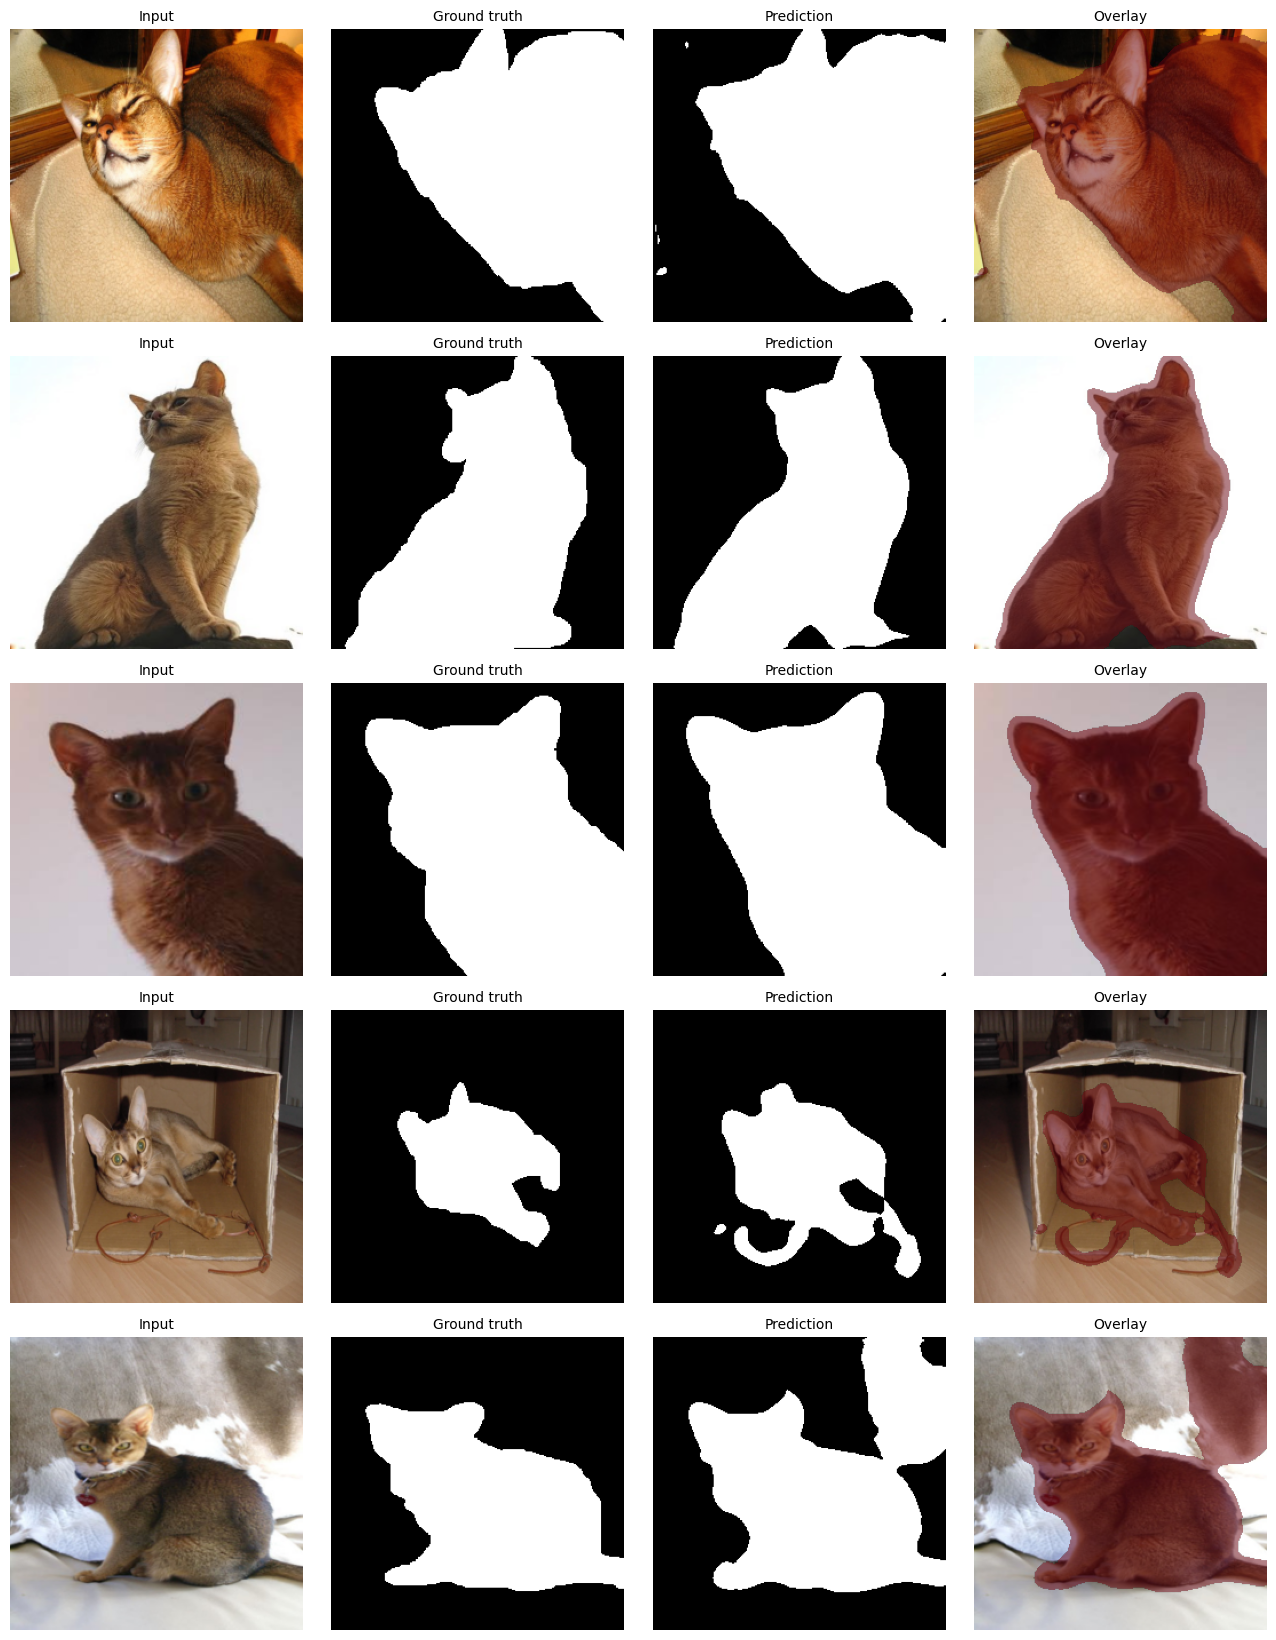

In [34]:
unet.eval()
# WRITE YOUR CODE HERE
testImages, testMasks = next(iter(seg_test_loader))
with torch.no_grad():
    predMasks = (torch.sigmoid(unet(testImages.to(device))) > 0.5).float().cpu()

numRows = min(5, len(testImages))
fig, axes = plt.subplots(numRows, 4, figsize=(13, 3.3 * numRows), squeeze=False)
columnTitles = ["Input", "Ground truth", "Prediction", "Overlay"]

for r in range(numRows):
    shownImg = denorm(testImages[r])
    trueMask = testMasks[r, 0].numpy()
    predMask = predMasks[r, 0].numpy()

    axes[r][0].imshow(shownImg)
    axes[r][1].imshow(trueMask, cmap="gray", vmin=0, vmax=1)
    axes[r][2].imshow(predMask, cmap="gray", vmin=0, vmax=1)
    # overlay: the image, then only the predicted pet pixels drawn on top in red
    axes[r][3].imshow(shownImg)
    axes[r][3].imshow(np.ma.masked_where(predMask == 0, predMask), cmap="Reds", vmin=0, vmax=1, alpha=0.5)

    for c in range(4):
        axes[r][c].set_title(columnTitles[c], fontsize=10)
        axes[r][c].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "unet_predictions.png"), dpi=150, bbox_inches="tight")
plt.show()

## Results Tables (fill in with YOUR results)
| ResNet-50 Metric | Result |
| --- | ---: |
| Training Accuracy | 1.000 |
| Validation Accuracy | 0.967 |
| Test Accuracy | 1.000 |
| Precision (macro) | 1.000 |
| Recall (macro) | 1.000 |
| F1-score (macro) | 1.000 |

| U-Net Metric | Result |
| --- | ---: |
| Training Loss | 0.1031 |
| Validation Loss | 0.4055 |
| Test Dice | 0.9237 |
| Test IoU | 0.8639 |

| Model | Dataset | Task | Main Metric | Result |
| --- | --- | --- | --- | ---: |
| ResNet-50 | Oxford Flowers-102 | Classification | Accuracy | 1.000 |
| U-Net | Oxford-IIIT Pet | Segmentation | Dice / IoU | 0.924 / 0.864 |

---
# Uploading the Assignment to GitHub (Detailed Procedure)

**GitHub** is a website that stores your project in a *repository* ("repo") with full version history.

## 1. What to upload
```text
resnet-unet-finetuning-assignment/
│
├── notebook/
│   └── assignment_resnet_unet.ipynb      <- this notebook, saved WITH outputs
│
├── results/
│   ├── resnet_results.png
│   ├── resnet_confusion_matrix.png
│   ├── unet_predictions.png
│   ├── unet_curves.png
│   └── (csv tables)
│

```
**Do NOT upload:** the datasets, or the trained weights (`*.pth`). GitHub rejects any single file larger than **100 MB**, and a U-Net with a ResNet-50 encoder is larger than that. Put the dataset link in the README and share the weights through a Google Drive link if required.

## 2. Prepare the files from Colab
1. Make sure the notebook was run **top to bottom** so that all outputs/figures are visible.
2. **Download the notebook:** `File -> Download -> Download .ipynb`.
3. **Download the results:** your figures are in `/content/results` and in `MyDrive/DL_Assignment/results` (open the Colab *Files* sidebar, or download them from Drive).


## 3.Create a GitHub account and repository
1. Go to **https://github.com** -> **Sign up** (skip if you already have an account) and verify your e-mail.
2. Click the **+** icon (top right) -> **New repository**.
3. **Repository name:** `[Roll_no]-assignment`
4. **Description:** *Fine-tuning ResNet-50 and U-Net on small image datasets*.
5. Choose **Public** (or Private and add your instructor as a collaborator: *Settings -> Collaborators*).
6. then click **Create repository**.
## 4 - Command line (Git)
Run this on your computer in the project folder (install Git from https://git-scm.com).

```bash
# one-time configuration (use your GitHub name and e-mail)
git config --global user.name  "Your Name"
git config --global user.email "you@example.com"

# create the local repository and make the first commit
git init
git add .
git commit -m "Complete ResNet and U-Net assignment"
git branch -M main

# connect to GitHub and upload
git remote add origin https://github.com/<your-username>/resnet-unet-finetuning-assignment.git
git push -u origin main
```
* GitHub **no longer accepts your account password** for `git push`. When asked for a password, paste a **Personal Access Token**: GitHub -> *Settings -> Developer settings -> Personal access tokens -> Tokens (classic) -> Generate new token*, tick the `repo` scope, copy the token (it is shown only once). Never share a token or write it inside the notebook.
* If you created the repo with a README, run `git pull origin main --allow-unrelated-histories` once before pushing.
* To update later: `git add .` -> `git commit -m "message"` -> `git push`.
